# Denton Area Dining Hall — energy use, 2018–2025

Monthly meter data from `CSVs/` (96 months per meter). Each CSV holds one building's monthly readings plus a `Total` row, which is checked against the monthly sum and then dropped.

| File | Meter | Unit |
|---|---|---|
| Electricity.csv | Building electricity | kWh |
| chiller.csv | Chiller electricity | kWh |
| emergency.csv | Emergency electricity | kWh |
| naturalgas.csv | Natural gas | therms |
| steam.csv | Steam | lbs |
| Total Energy.csv | All sources combined | kBtu |

Plots are saved to `plots/`.

In [22]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates

CSV_DIR = Path("CSVs")
PLOT_DIR = Path("plots")
PLOT_DIR.mkdir(exist_ok=True)

# Chart chrome and palette (validated categorical order; blue is the single-series / sequential hue)
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
BLUE = SERIES[0]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 1, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.titlesize": 11, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "legend.frameon": False, "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

def compact(x, _=None):
    for div, suf in ((1e9, "B"), (1e6, "M"), (1e3, "K")):
        if abs(x) >= div:
            return f"{x/div:,.2f}".rstrip("0").rstrip(".") + suf
    return f"{x:,.0f}"

In [23]:
def load_meter(path):
    raw = pd.read_csv(path, header=None, names=["label", "value"], encoding="utf-8-sig")
    building = raw.iloc[0, 1]
    raw = raw.iloc[1:]
    is_total = raw["label"].str.startswith("Total")
    total = float(raw.loc[is_total, "value"].iloc[0])
    rows = raw[~is_total]
    unit = re.search(r"\((.+)\)", rows["label"].iloc[0]).group(1)
    dates = pd.to_datetime(rows["label"].str.replace(r"\s*\(.+\)", "", regex=True), format="%b %Y")
    s = pd.Series(rows["value"].astype(float).values, index=dates, name=path.stem)
    assert np.isclose(s.sum(), total, rtol=1e-6), f"{path.name}: monthly sum != Total row"
    return building, unit, s

METERS = {  # file stem -> display name
    "Electricity": "Electricity", "chiller": "Chiller", "emergency": "Emergency",
    "naturalgas": "Natural gas", "steam": "Steam", "Total Energy": "Total energy",
}
series, units = {}, {}
for stem, name in METERS.items():
    building, unit, s = load_meter(CSV_DIR / f"{stem}.csv")
    series[name], units[name] = s, unit
df = pd.DataFrame(series)
print(building, "|", f"{df.index.min():%b %Y} – {df.index.max():%b %Y}", f"({len(df)} months)")

Denton Area Dining Hall | Jan 2018 – Dec 2025 (96 months)


In [24]:
df.describe().T.assign(unit=pd.Series(units)).round(1)

,count,mean,std,min,25%,50%,75%,max,unit
Electricity,96.0,99161.9,27628.4,46140.0,75100.5,102000.0,122107.0,153014.0,kWh
Chiller,96.0,38388.5,31636.7,0.0,11657.4,31067.5,64371.3,134469.9,kWh
Emergency,96.0,139.2,225.6,0.0,50.0,54.9,61.3,1277.7,kWh
Natural gas,96.0,1556.5,977.5,0.0,808.4,1600.7,2395.5,3523.9,Therms
Steam,96.0,458574.8,311698.9,300.0,196475.0,417800.0,701100.0,1271100.0,lbs
Total energy,96.0,1090002.7,366119.3,291273.9,823108.5,1145989.6,1348038.2,1763102.9,kBtu


## How Total Energy is built

Regressing the Total Energy column on the five meters gives a near-exact fit:

**Total kBtu = 3.412 × (Electricity + Chiller + Emergency) kWh + 100 × Gas therms + 1.013 × Steam lbs**

(3.412 kBtu/kWh and 100 kBtu/therm are the standard factors; ~1.013 kBtu/lb is the steam factor used in the source data.) So every meter can be put into kBtu and stacked to show where the energy comes from.

In [25]:
KBTU_PER = {"Electricity": 3.412, "Chiller": 3.412, "Emergency": 3.412, "Natural gas": 100.0, "Steam": 1.013}
SOURCES = ["Steam", "Natural gas", "Electricity", "Chiller", "Emergency"]  # stacking order, largest first
kbtu = pd.DataFrame({k: df[k] * f for k, f in KBTU_PER.items()})[SOURCES]

resid = (kbtu.sum(axis=1) - df["Total energy"]).abs()
print(f"max |reconstructed − reported| = {resid.max():.4f} kBtu")
# small residuals sit in low-steam summer months, where the source's steam conversion drifts from 1.013

max |reconstructed − reported| = 34.0434 kBtu


## 1 · Monthly use per meter
Each meter on its own axis (units differ), with a 12-month rolling mean to show the trend under the seasonality.

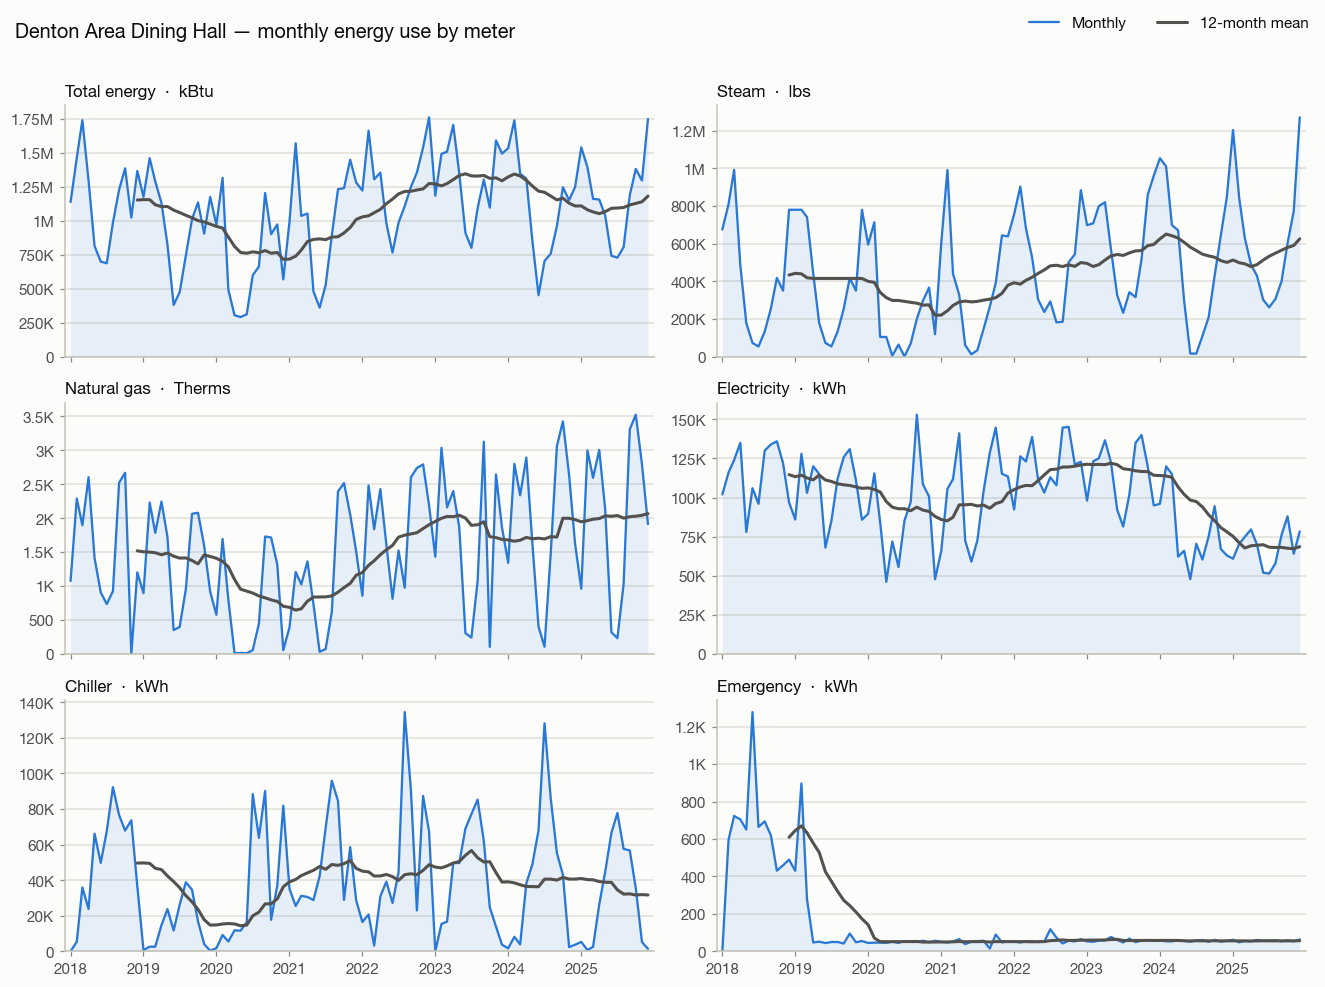

In [26]:
order = ["Total energy", "Steam", "Natural gas", "Electricity", "Chiller", "Emergency"]
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
for ax, name in zip(axes.flat, order):
    s = df[name]
    ax.fill_between(s.index, s, color=BLUE, alpha=0.10, linewidth=0)
    ax.plot(s.index, s, color=BLUE, linewidth=1.5, label="Monthly")
    ax.plot(s.index, s.rolling(12).mean(), color=INK2, linewidth=2, label="12-month mean")
    ax.set_title(f"{name}  ·  {units[name]}")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(compact))
    ax.set_ylim(bottom=0)
    ax.margins(x=0.01)
h, l = axes.flat[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", ncol=2, bbox_to_anchor=(1, 1.0))
fig.suptitle(f"{building} — monthly energy use by meter", x=0.01, ha="left", fontsize=13, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(PLOT_DIR / "01_monthly_by_meter.png")
plt.show()

## 2 · Annual energy by source (kBtu)

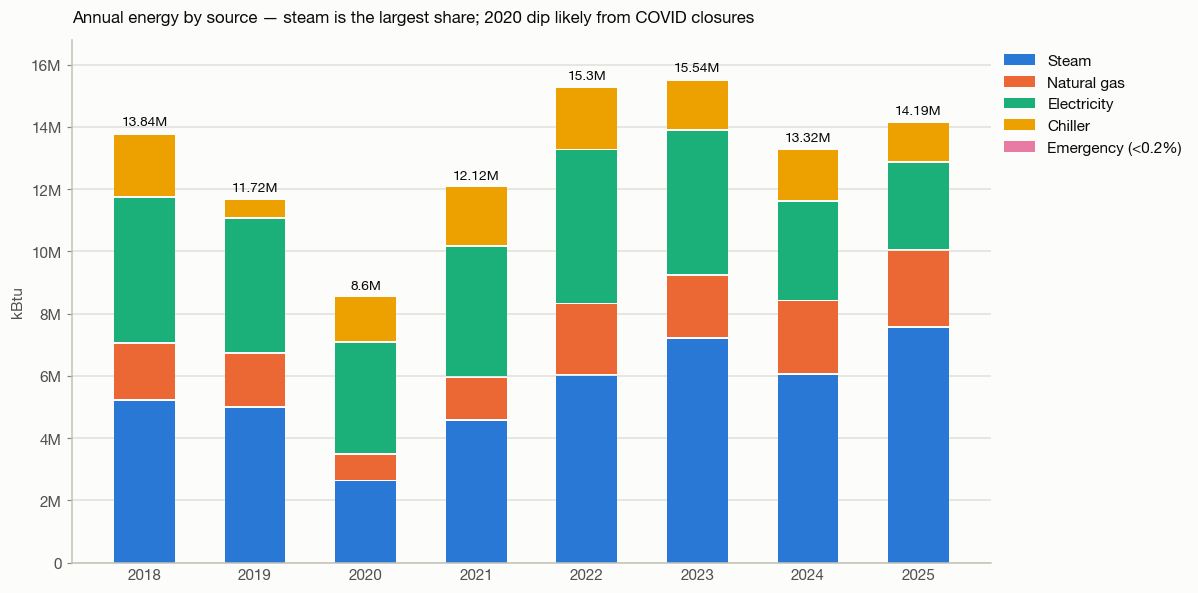

,Steam,Natural gas,Electricity,Chiller,Emergency,Total (M kBtu)
label,,,,,,
2018,38.1,13.2,33.9,14.7,0.2,13.84
2019,43.1,14.7,37.0,5.1,0.1,11.72
2020,31.0,9.8,41.9,17.3,0.0,8.60
2021,38.0,11.5,34.7,15.7,0.0,12.12
2022,39.7,14.9,32.3,13.0,0.0,15.30
2023,46.6,13.0,30.1,10.3,0.0,15.54
2024,45.7,17.8,24.0,12.5,0.0,13.32
2025,53.6,17.5,19.8,9.1,0.0,14.19


In [27]:
annual = kbtu.resample("YE").sum()
annual.index = annual.index.year
fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(annual))
bottom = np.zeros(len(annual))
gap = annual.sum(axis=1).max() * 0.004  # thin surface gap between stacked segments
for name, color in zip(SOURCES, SERIES):
    vals = annual[name].values
    ax.bar(x, np.maximum(vals - gap, 0), width=0.55, bottom=bottom, color=color, label=name if name != "Emergency" else "Emergency (<0.2%)", linewidth=0)
    bottom += vals
for xi, tot in zip(x, bottom):
    ax.text(xi, tot * 1.01, compact(tot), ha="center", va="bottom", color=INK, fontsize=9)
ax.set_xticks(x, annual.index)
ax.set_ylim(0, bottom.max() * 1.08)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(compact))
ax.set_ylabel("kBtu")
ax.set_title("Annual energy by source — steam is the largest share; 2020 dip likely from COVID closures", pad=12)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.tick_params(axis="x", length=0)
fig.tight_layout()
fig.savefig(PLOT_DIR / "02_annual_by_source.png")
plt.show()

share = annual.div(annual.sum(axis=1), axis=0).mul(100).round(1)
share.assign(**{"Total (M kBtu)": (annual.sum(axis=1) / 1e6).round(2)})

## 3 · Seasonality
Average for each calendar month across 2018–2025. Heating loads (steam, gas) peak in winter; the chiller peaks in summer.

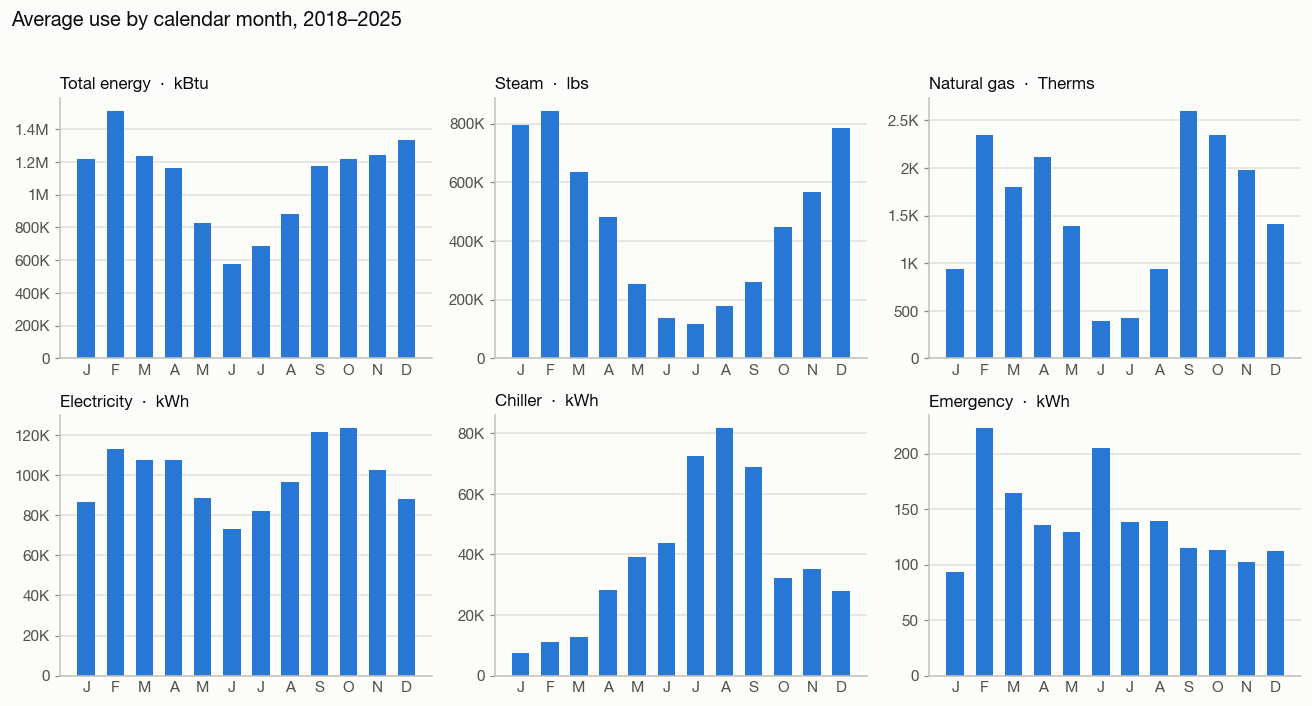

In [28]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
months = ["J","F","M","A","M","J","J","A","S","O","N","D"]
for ax, name in zip(axes.flat, order):
    prof = df[name].groupby(df.index.month).mean()
    ax.bar(prof.index, prof.values, width=0.6, color=BLUE, linewidth=0)
    ax.set_title(f"{name}  ·  {units[name]}")
    ax.set_xticks(range(1, 13), months)
    ax.tick_params(axis="x", length=0)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(compact))
fig.suptitle("Average use by calendar month, 2018–2025", x=0.01, ha="left", fontsize=13, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(PLOT_DIR / "03_seasonal_profile.png")
plt.show()

## 4 · Total energy heatmap (year × month)

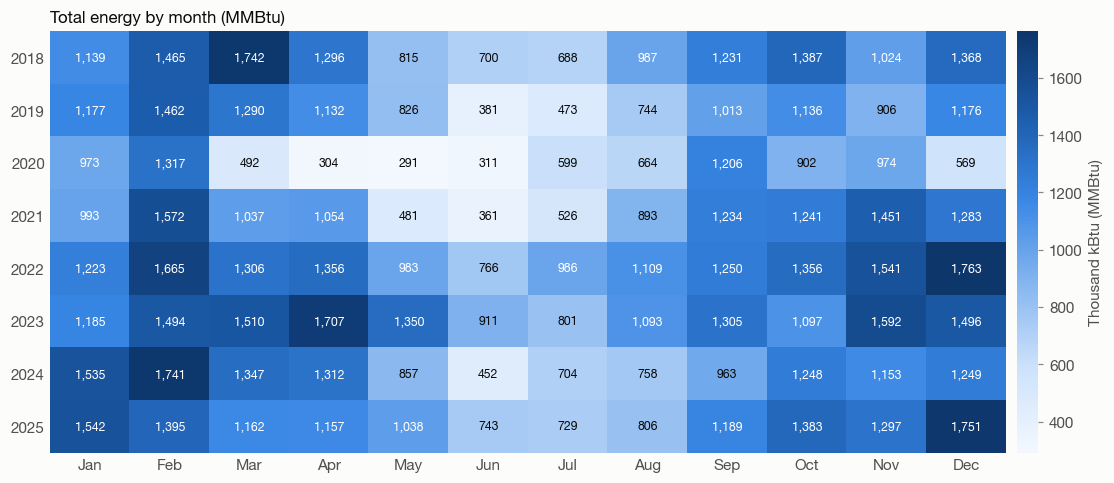

In [29]:
from matplotlib.colors import LinearSegmentedColormap
blues = LinearSegmentedColormap.from_list("seq_blue", ["#f3f8fe", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
grid = df["Total energy"].groupby([df.index.year, df.index.month]).sum().unstack()
fig, ax = plt.subplots(figsize=(11, 4.5))
im = ax.imshow(grid.values / 1e3, cmap=blues, aspect="auto")
ax.set_xticks(range(12), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_yticks(range(len(grid)), grid.index)
ax.grid(False)
for sp in ax.spines.values(): sp.set_visible(False)
ax.tick_params(length=0)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j] / 1e3
        ax.text(j, i, f"{v:,.0f}", ha="center", va="center", fontsize=8,
                color="white" if v > np.nanmax(grid.values) / 1e3 * 0.55 else INK)
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("Thousand kBtu (MMBtu)", color=INK2)
cb.outline.set_visible(False)
ax.set_title("Total energy by month (MMBtu)")
fig.tight_layout()
fig.savefig(PLOT_DIR / "04_total_energy_heatmap.png")
plt.show()

## 5 · Year-over-year change per meter

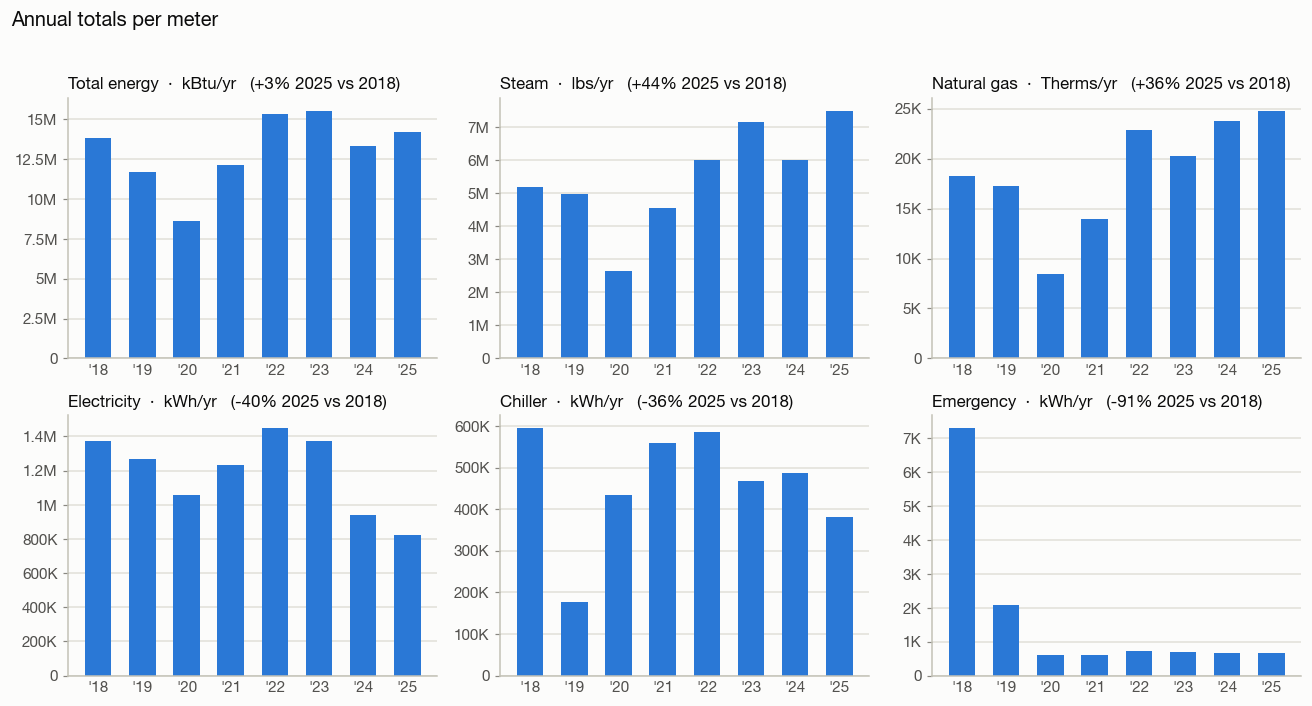

,Electricity,Chiller,Emergency,Natural gas,Steam,Total energy
label,,,,,,
2018,1376000,595254,7308,18232,5199900,13841855
2019,1270846,176727,2085,17227,4981600,11715463
2020,1055715,435106,595,8421,2635955,8601242
2021,1234449,559110,619,13918,4551900,12124848
2022,1450371,584539,713,22844,5996600,15304832
2023,1371143,467129,692,20247,7148700,15541154
2024,937649,487242,669,23738,6002700,13318759
2025,823365,380188,678,24797,7505827,14192109


In [30]:
yearly = df.resample("YE").sum()
yearly.index = yearly.index.year
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, name in zip(axes.flat, order):
    y = yearly[name]
    ax.bar(y.index, y.values, width=0.6, color=BLUE, linewidth=0)
    ax.set_xticks(y.index, [f"'{str(v)[2:]}" for v in y.index])
    ax.tick_params(axis="x", length=0)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(compact))
    chg = (y.iloc[-1] / y.iloc[0] - 1) * 100
    ax.set_title(f"{name}  ·  {units[name]}/yr   ({chg:+.0f}% 2025 vs 2018)")
fig.suptitle("Annual totals per meter", x=0.01, ha="left", fontsize=13, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(PLOT_DIR / "05_annual_by_meter.png")
plt.show()

yearly.round(0).astype(int)

## 6 · Data-quality flags
Months that are zero or far below the meter's own median for that calendar month (< 25%) — possible meter outages/gaps (or, for spring–summer 2020, the COVID shutdown). Chiller and Emergency are skipped: chiller winter lows and emergency spikes are normal for those meters.

In [31]:
flags = []
for name in ["Total energy", "Steam", "Natural gas", "Electricity"]:
    s = df[name]
    med = s.groupby(s.index.month).transform("median")
    bad = s[(s == 0) | (s < 0.25 * med)]
    for d, v in bad.items():
        flags.append({"meter": name, "month": f"{d:%b %Y}", "value": round(v, 1), "typical for month": round(med[d], 1)})
pd.DataFrame(flags)

,meter,month,value,typical for month
0,Total energy,Apr 2020,304322.8,1226720.2
1,Steam,Mar 2020,104105.0,690550.0
2,Steam,Apr 2020,104150.0,487050.0
3,Steam,May 2020,4600.0,237650.0
4,Steam,Jul 2020,300.0,53600.0
5,Steam,Dec 2020,119000.0,813800.0
6,Steam,Jun 2021,11900.0,72500.0
7,Steam,Jun 2024,16256.0,72500.0
8,Natural gas,Nov 2018,0.0,2345.3
9,Natural gas,Apr 2020,10.3,2413.8


## 7 · Meter gaps & outages timeline
Every month of every meter, classified against that meter's own median for the same calendar month (so normal seasonal lows, like chiller in winter, are not flagged):

- **Zero reading** — meter reported 0
- **< 25% of typical** — likely outage or partial data
- **25–50% of typical** — unusually low
- **Repeated value** — identical to the previous month (to the last decimal), suggesting an estimated or held reading rather than a real meter read
- **Copied from prior year** — identical to the same month one year earlier (e.g. steam May–Dec 2019 is an exact copy of May–Dec 2018)

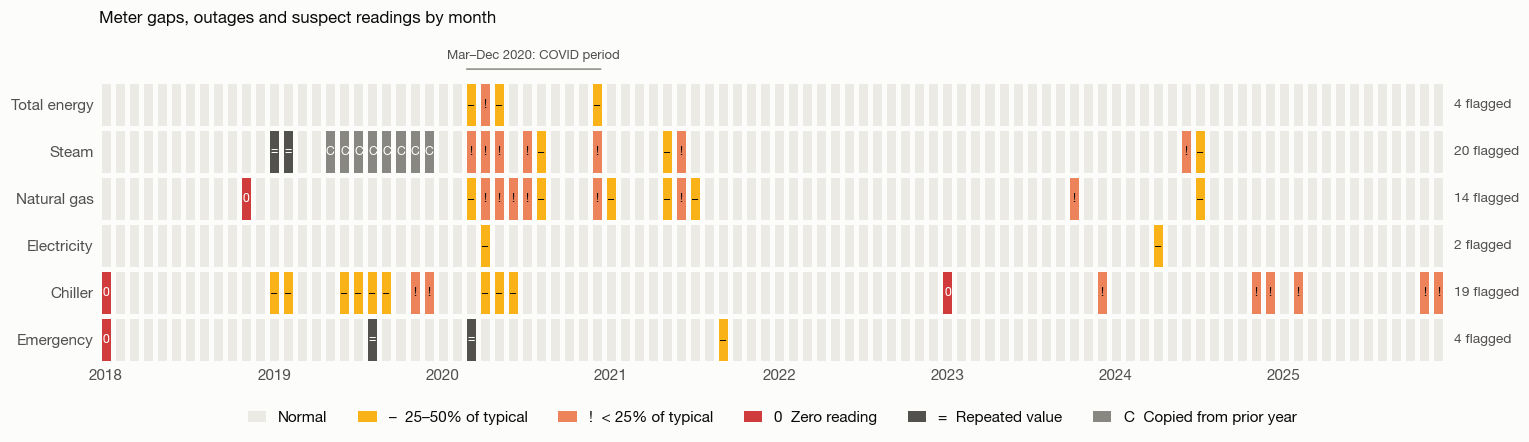

,month,meter,issue,value
0,Jan 2018,Chiller,Zero reading,0.0
4,Jan 2019,Chiller,25–50% of typical,691.2
6,Feb 2019,Chiller,25–50% of typical,2601.5
9,Jun 2019,Chiller,25–50% of typical,11683.6
11,Jul 2019,Chiller,25–50% of typical,26055.2
...,...,...,...,...
56,Jul 2024,Steam,25–50% of typical,15544.0
22,Mar 2020,Total energy,25–50% of typical,492242.9
26,Apr 2020,Total energy,< 25% of typical,304322.8
31,May 2020,Total energy,25–50% of typical,291273.9


In [32]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

STATES = [  # (code, label, colour, glyph)
    (0, "Normal",               "#ebeae5", ""),
    (1, "25–50% of typical",    "#fab219", "–"),
    (2, "< 25% of typical",     "#ec835a", "!"),
    (3, "Zero reading",         "#d03b3b", "0"),
    (4, "Repeated value",       "#52514e", "="),
    (5, "Copied from prior year", "#898781", "C"),
]
rows = ["Total energy", "Steam", "Natural gas", "Electricity", "Chiller", "Emergency"]

def classify(s):
    typical = s.groupby(s.index.month).transform("median")
    ratio = s / typical
    state = pd.Series(0, index=s.index)
    state[ratio < 0.5] = 1
    state[ratio < 0.25] = 2
    state[s == 0] = 3
    state[(s == s.shift()) & (s != 0)] = 4
    state[(s == s.shift(12)) & (s != 0)] = 5
    return state

status = pd.DataFrame({m: classify(df[m]) for m in rows}).T

fig, ax = plt.subplots(figsize=(14, 4.2))
cmap = ListedColormap([c for _, _, c, _ in STATES])
ax.pcolormesh(np.arange(len(status.columns) + 1), np.arange(len(rows) + 1), status.values,
              cmap=cmap, norm=BoundaryNorm(np.arange(-0.5, len(STATES)), cmap.N),
              edgecolors=SURFACE, linewidth=2)
for i, m in enumerate(rows):
    for j, v in enumerate(status.loc[m].values):
        if v:
            ax.text(j + 0.5, i + 0.5, STATES[v][3], ha="center", va="center", fontsize=8,
                    fontweight="bold", color="white" if v in (3, 4, 5) else INK)
    n = int((status.loc[m] > 0).sum())
    ax.text(len(status.columns) + 0.6, i + 0.5, f"{n} flagged", va="center", fontsize=9, color=INK2)

ax.invert_yaxis()
ax.set_yticks(np.arange(len(rows)) + 0.5, rows)
jan = [j for j, d in enumerate(status.columns) if d.month == 1]
ax.set_xticks(np.array(jan) + 0.5, [status.columns[j].year for j in jan])
ax.grid(False)
for sp in ax.spines.values(): sp.set_visible(False)
ax.tick_params(length=0)
ax.set_xlim(0, len(status.columns))

# bracket the 2020 COVID period so those lows aren't mistaken for meter faults
c0, c1 = status.columns.get_loc(pd.Timestamp("2020-03-01")), status.columns.get_loc(pd.Timestamp("2020-12-01")) + 1
ax.annotate("", xy=(c0, -0.25), xytext=(c1, -0.25), annotation_clip=False,
            arrowprops=dict(arrowstyle="-", color=MUTED, linewidth=1))
ax.text((c0 + c1) / 2, -0.4, "Mar–Dec 2020: COVID period", ha="center", va="bottom", fontsize=8.5, color=INK2)

ax.legend(handles=[Patch(facecolor=c, label=f"{g}  {l}".strip()) for _, l, c, g in STATES],
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=6, handlelength=1.2)
ax.set_title("Meter gaps, outages and suspect readings by month", pad=38)
fig.tight_layout()
fig.savefig(PLOT_DIR / "06_meter_gaps_timeline.png")
plt.show()

flagged = status.T.stack().loc[lambda x: x > 0].rename("state").reset_index()
flagged.columns = ["month", "meter", "state"]
flagged["issue"] = flagged["state"].map({c: l for c, l, _, _ in STATES})
flagged["value"] = [round(df.at[d, m], 1) for d, m in zip(flagged.month, flagged.meter)]
flagged["month"] = flagged["month"].dt.strftime("%b %Y")
flagged.drop(columns="state").sort_values(["meter", "month"], key=lambda c: c if c.name == "meter" else pd.to_datetime(c, format="%b %Y"))

## 8 · Monthly consumption by category
One chart per category: every month from Jan 2018 to Dec 2025 in its native unit, with the highest month labelled and the annual total under each year.

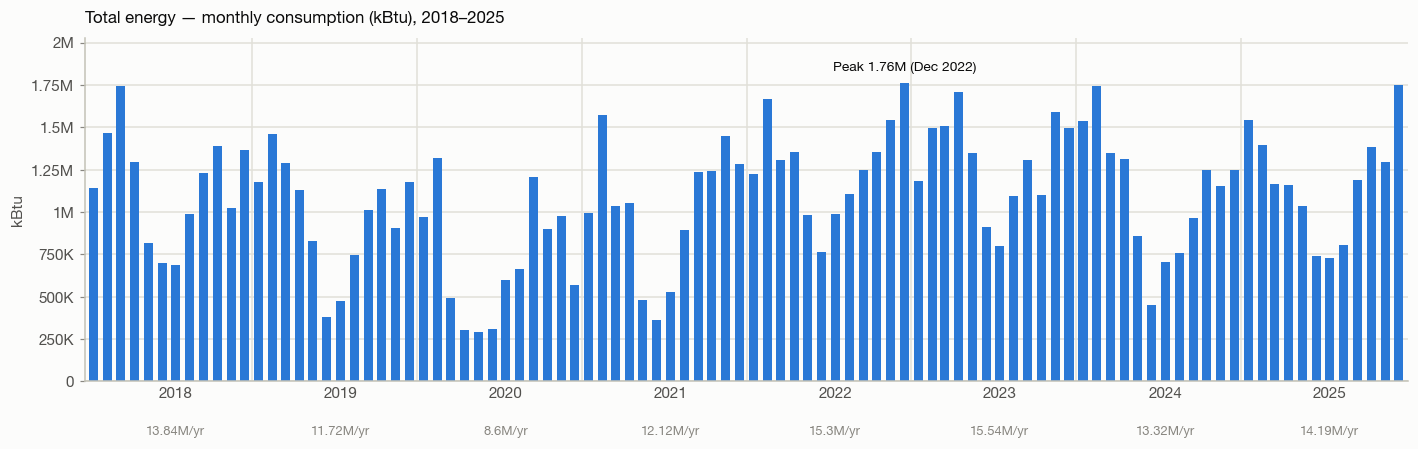

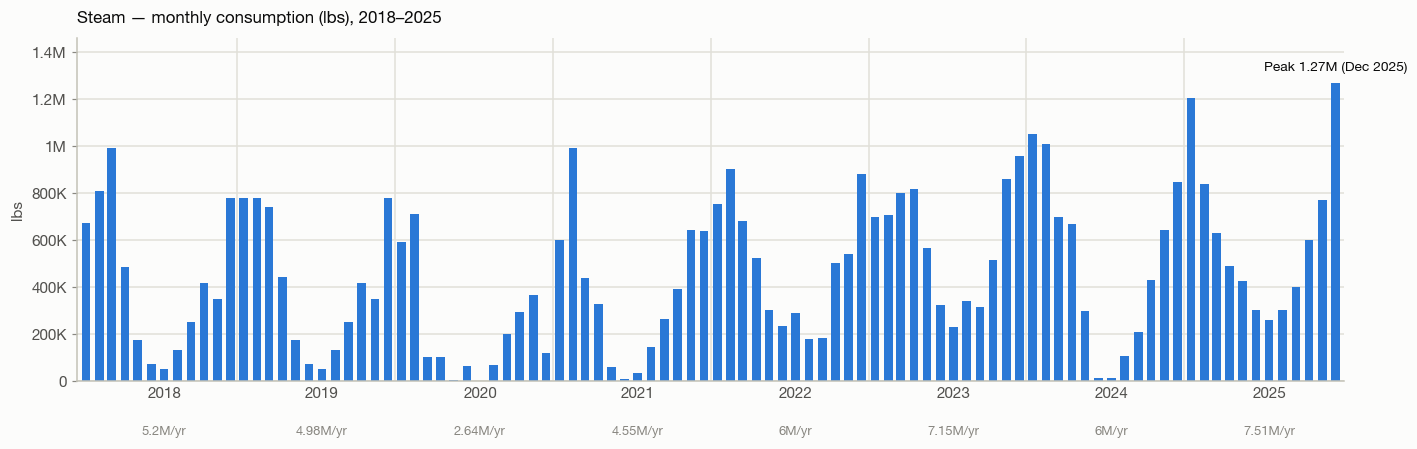

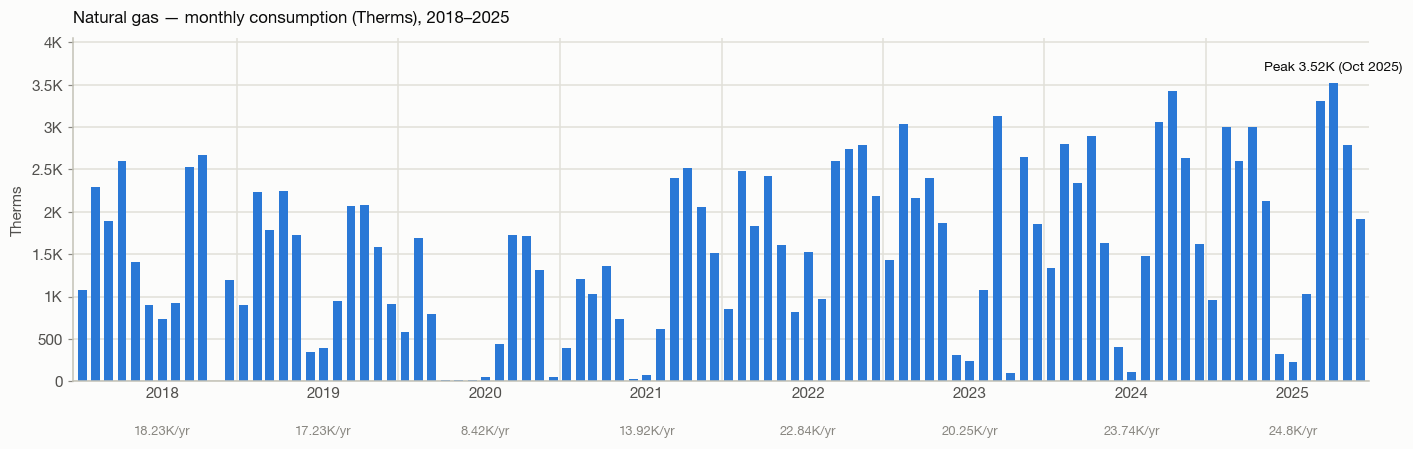

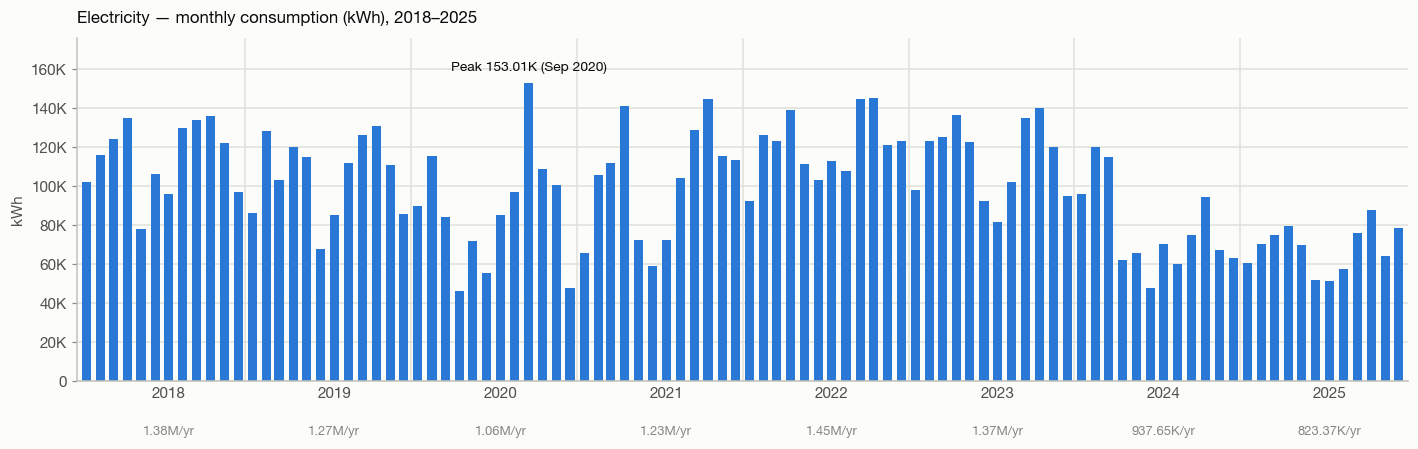

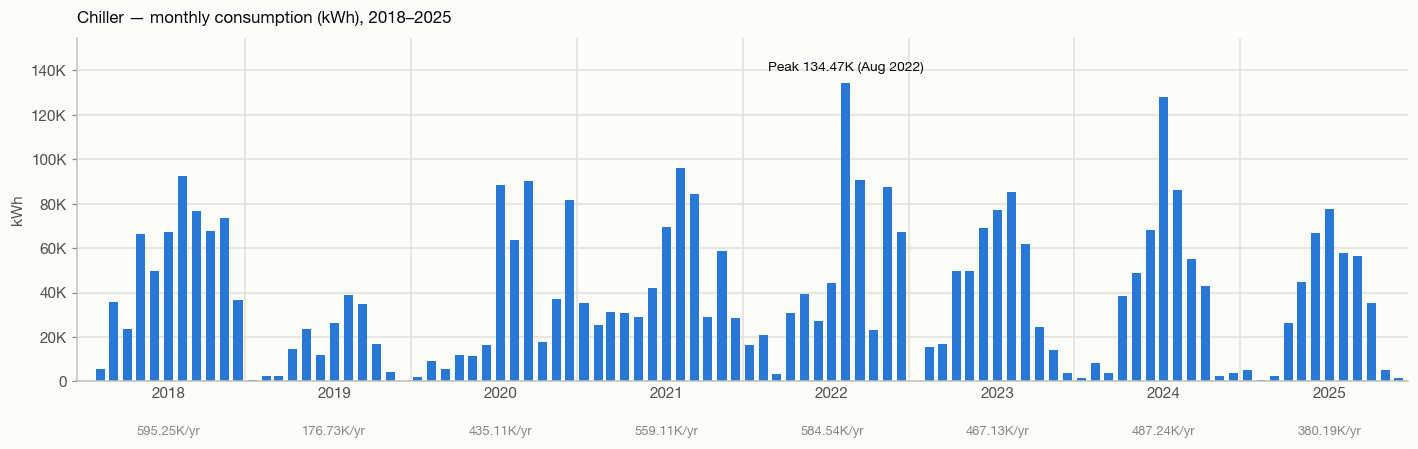

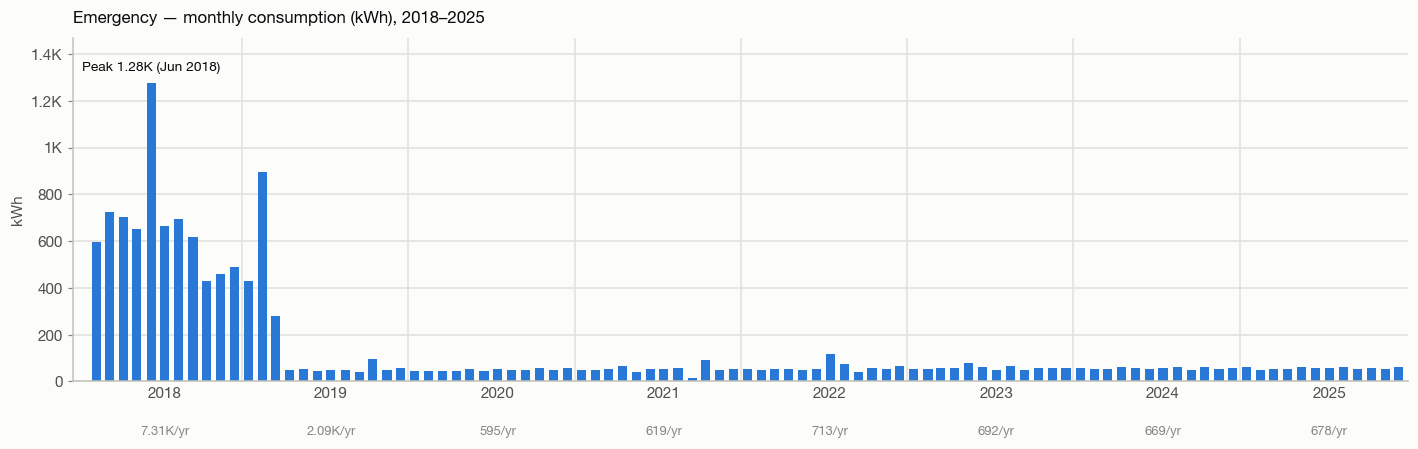

In [33]:
FILE_SLUG = {"Total energy": "total_energy", "Steam": "steam", "Natural gas": "natural_gas",
             "Electricity": "electricity", "Chiller": "chiller", "Emergency": "emergency"}

for i, name in enumerate(rows, start=7):
    s = df[name]
    fig, ax = plt.subplots(figsize=(13, 4.2))
    ax.bar(s.index, s.values, width=20, color=BLUE, linewidth=0)

    # year separators + annual totals
    for yr in range(s.index.year.min(), s.index.year.max() + 1):
        if yr > s.index.year.min():
            ax.axvline(pd.Timestamp(f"{yr}-01-01") - pd.Timedelta(days=15), color=GRID, linewidth=1, zorder=0)
        tot = s[str(yr)].sum()
        ax.text(pd.Timestamp(f"{yr}-07-01"), -0.13, f"{compact(tot)}/yr", transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=8.5, color=MUTED)

    peak = s.idxmax()
    ax.annotate(f"Peak {compact(s.max())} ({peak:%b %Y})", xy=(peak, s.max()), xytext=(0, 6),
                textcoords="offset points", ha="center", va="bottom", fontsize=9, color=INK)

    ax.set_ylim(0, s.max() * 1.15)
    ax.set_xlim(s.index.min() - pd.Timedelta(days=20), s.index.max() + pd.Timedelta(days=20))
    ax.xaxis.set_major_locator(mdates.YearLocator(month=7))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.tick_params(axis="x", length=0)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(compact))
    ax.set_ylabel(units[name])
    ax.set_title(f"{name} — monthly consumption ({units[name]}), 2018–2025", pad=10)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{i:02d}_monthly_{FILE_SLUG[name]}.png")
    plt.show()

## 9 · Seasonal decomposition (STL)
Each meter is split into three parts with STL (Seasonal-Trend decomposition using LOESS, 12-month period, 13-month seasonal smoother, robust fitting so outages don't distort the fit):

- **Trend** — the long-run level with the seasons removed
- **Seasonal** — the repeating within-year pattern (allowed to drift slowly over the years)
- **Residual** — what's left; large residuals are months that don't fit the usual pattern

Months whose residual is more than 3 robust standard deviations (MAD-based) from zero are marked as anomalies.

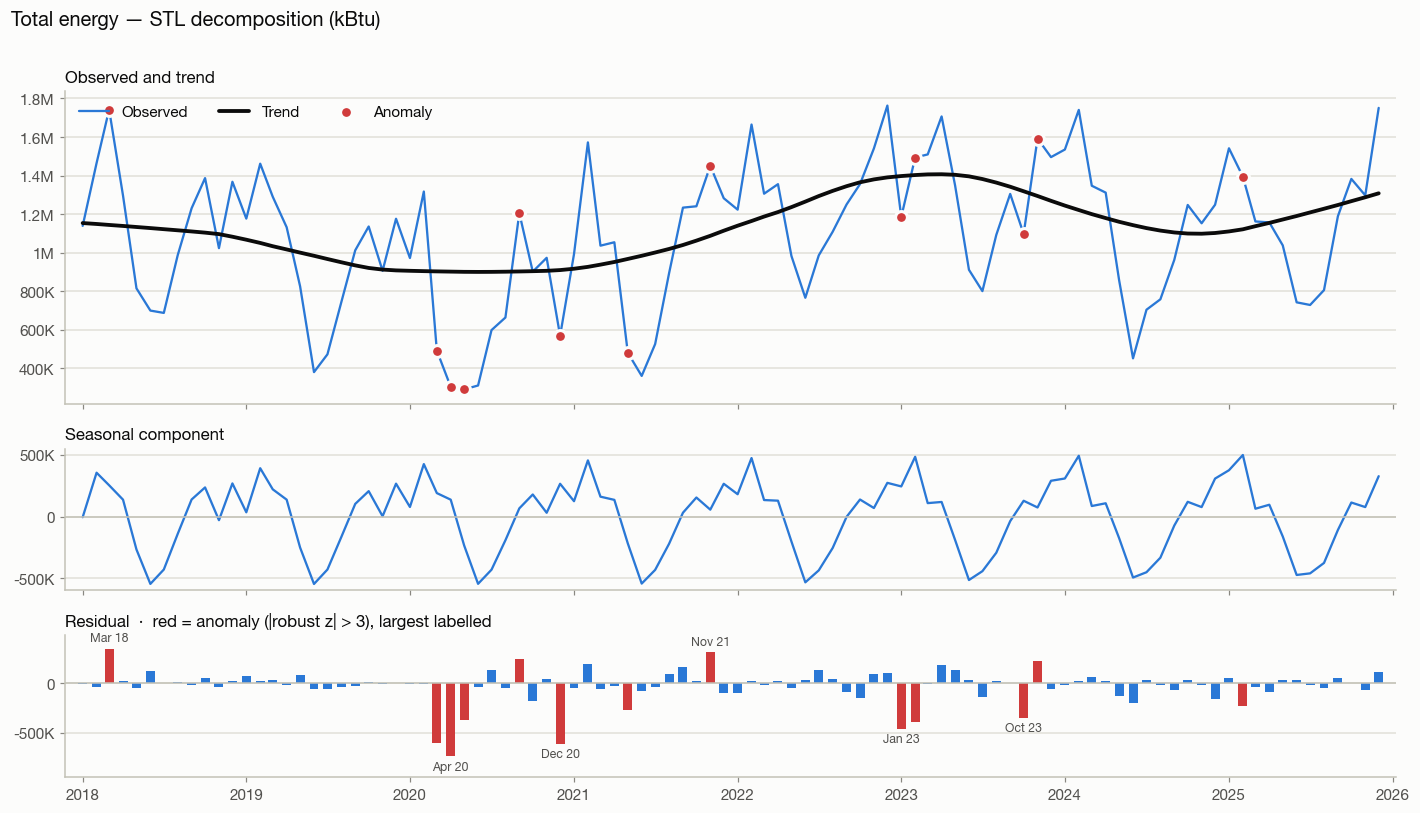

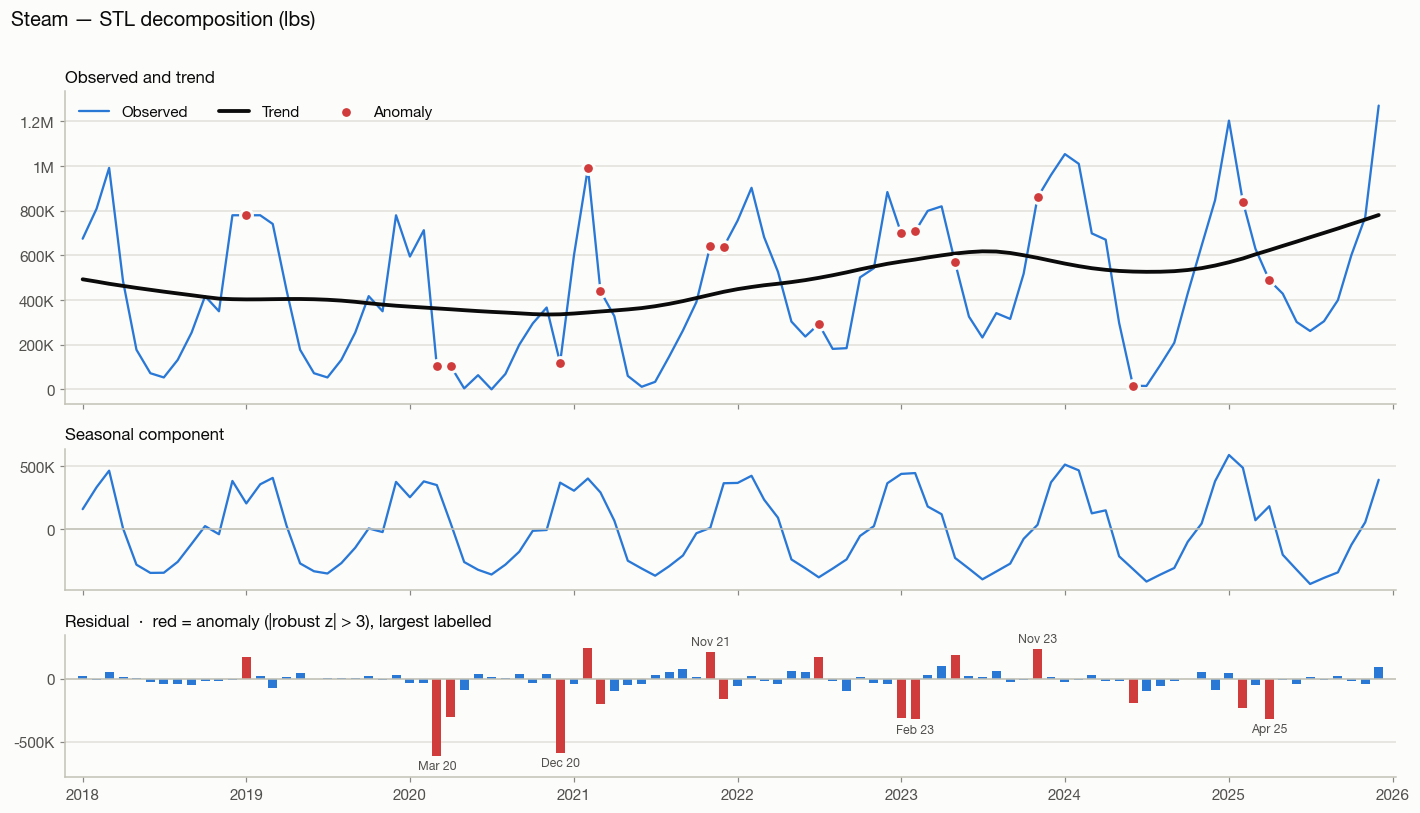

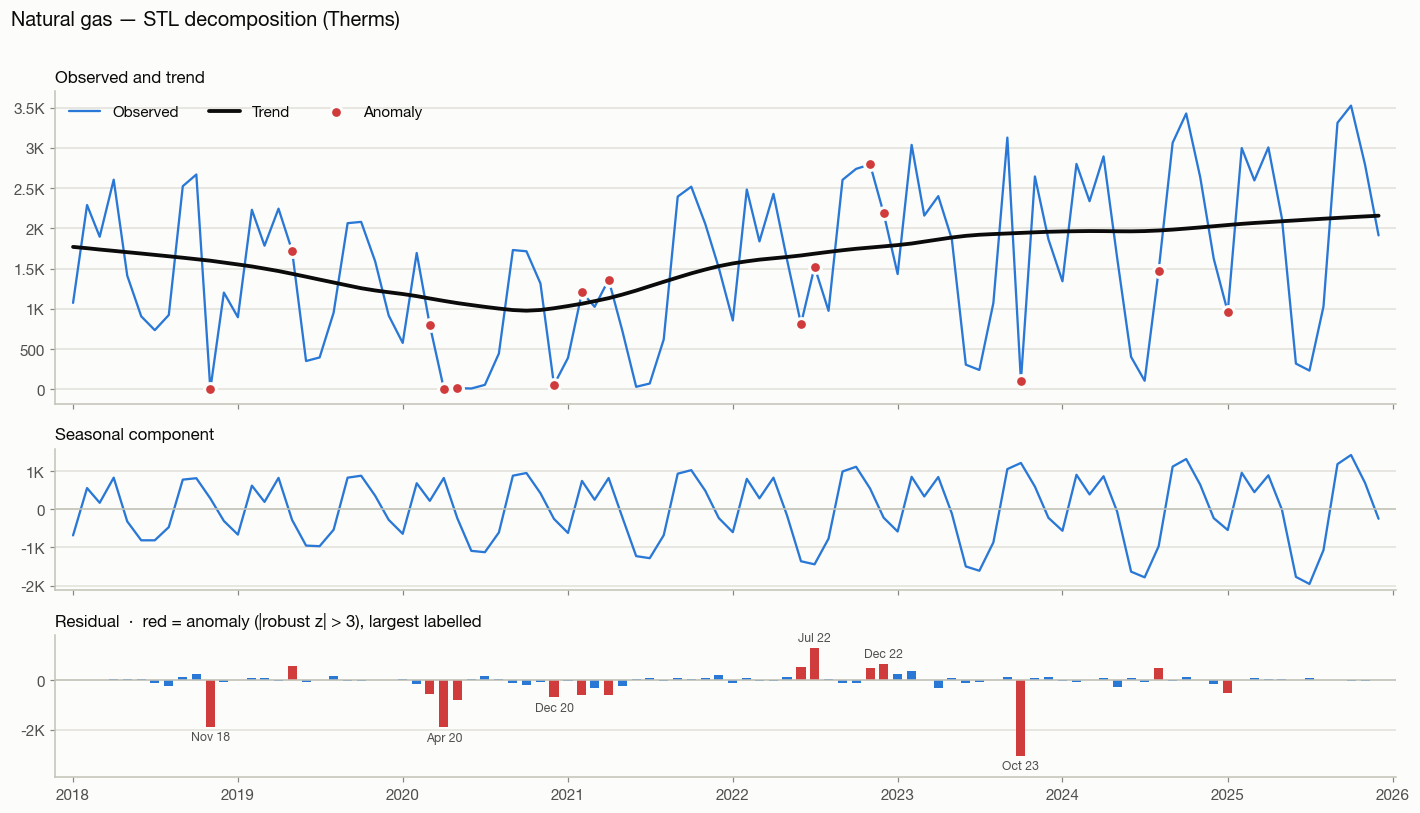

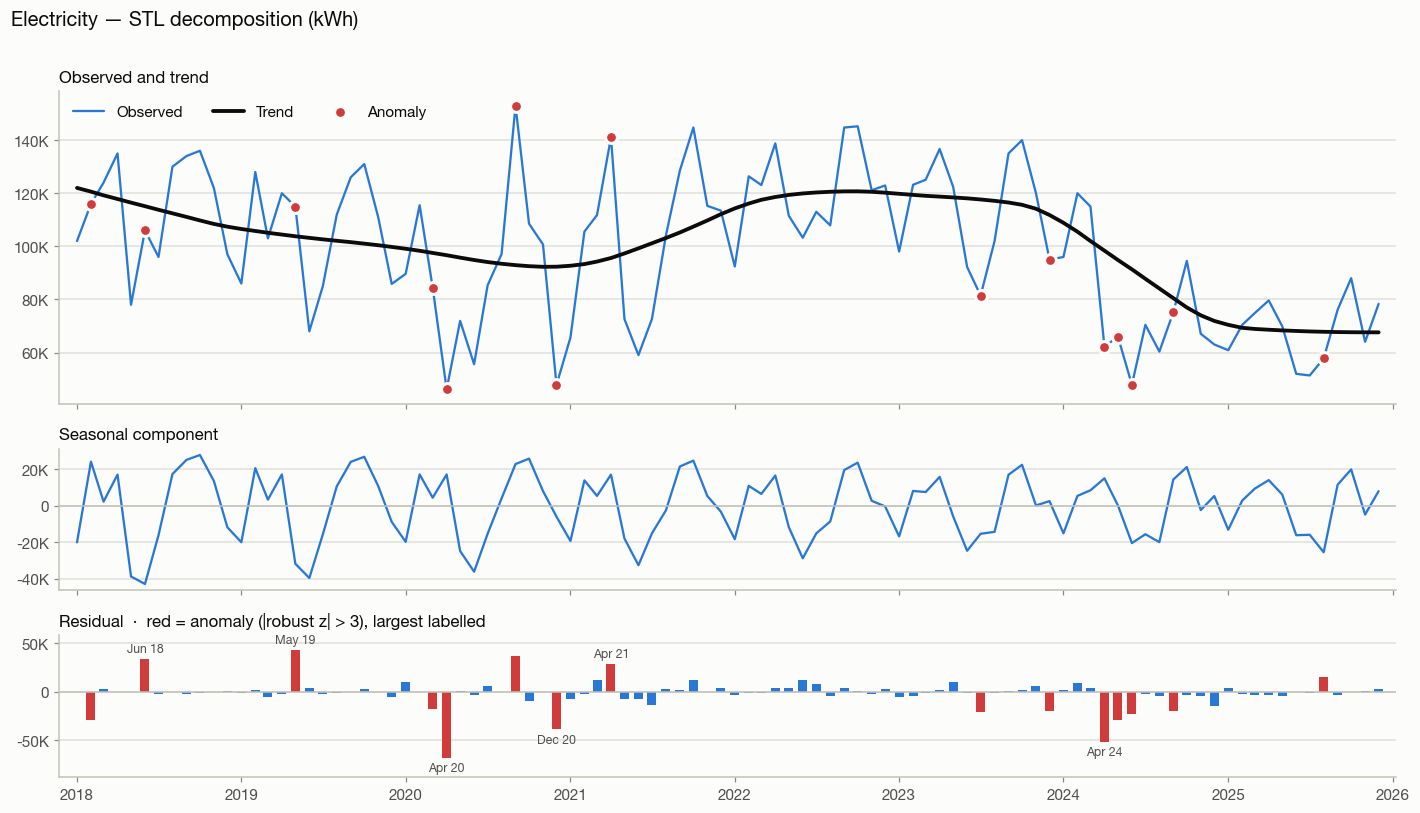

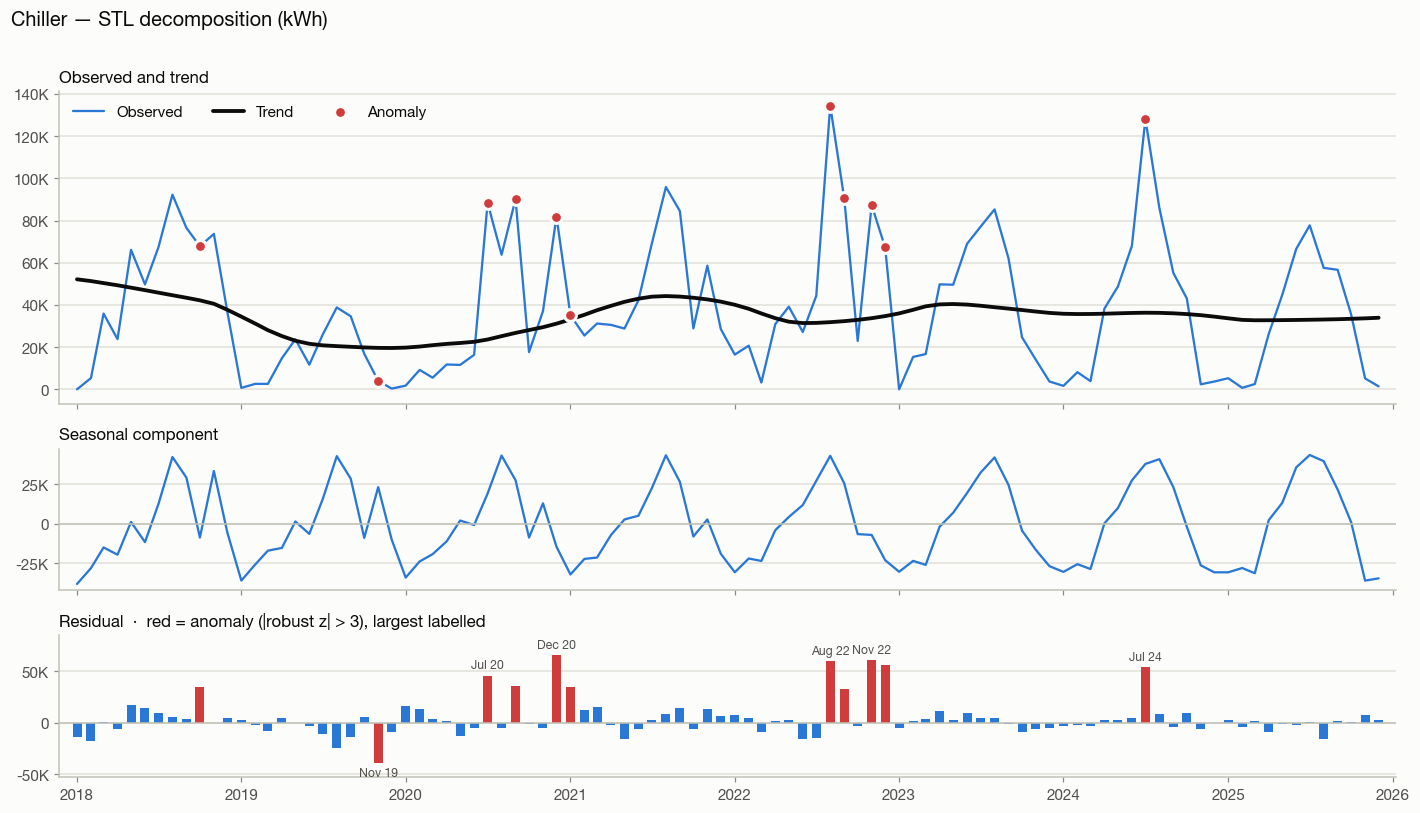

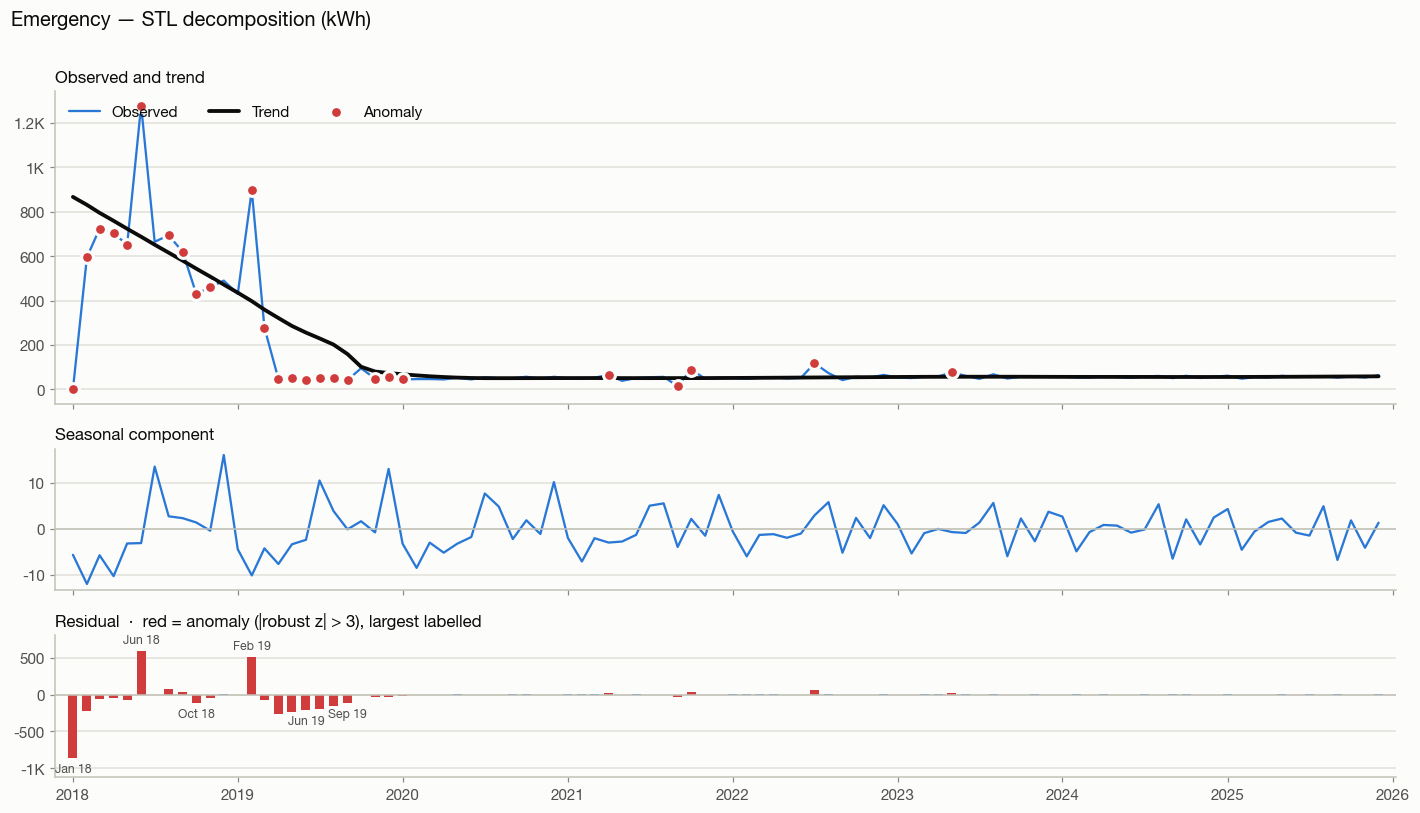

In [34]:
from statsmodels.tsa.seasonal import STL

def robust_z(r):
    mad = np.median(np.abs(r - np.median(r)))
    return (r - np.median(r)) / (1.4826 * mad) if mad else r * 0

stl_results, stl_rows = {}, []
for i, name in enumerate(rows, start=13):
    s = df[name].asfreq("MS")
    res = STL(s, period=12, seasonal=13, robust=True).fit()
    stl_results[name] = res
    z = robust_z(res.resid)
    anom = z[np.abs(z) > 3]

    fig, axes = plt.subplots(3, 1, figsize=(13, 7.5), sharex=True, gridspec_kw={"height_ratios": [2.2, 1, 1]})
    ax = axes[0]
    ax.plot(s.index, s, color=BLUE, linewidth=1.5, label="Observed")
    ax.plot(res.trend.index, res.trend, color=INK, linewidth=2.5, label="Trend")
    ax.scatter(anom.index, s[anom.index], s=60, color="#d03b3b", edgecolor=SURFACE, linewidth=2, zorder=3, label="Anomaly")
    ax.set_title("Observed and trend")
    ax.legend(loc="upper left", ncol=3)
    axes[1].plot(res.seasonal.index, res.seasonal, color=BLUE, linewidth=1.5)
    axes[1].axhline(0, color=AXIS, linewidth=1)
    axes[1].set_title("Seasonal component")
    ax = axes[2]
    ax.bar(res.resid.index, res.resid, width=20, color=BLUE, linewidth=0)
    ax.bar(anom.index, res.resid[anom.index], width=20, color="#d03b3b", linewidth=0)
    labelled = []
    for d in anom.abs().sort_values(ascending=False).index:  # label the largest few, never two within 3 months
        if len(labelled) == 6 or any(abs((d - l).days) < 92 for l in labelled):
            continue
        labelled.append(d)
        ax.annotate(f"{d:%b %y}", xy=(d, res.resid[d]), xytext=(0, 3 if res.resid[d] > 0 else -3),
                    textcoords="offset points", ha="center", va="bottom" if res.resid[d] > 0 else "top",
                    fontsize=8, color=INK2)
    ax.axhline(0, color=AXIS, linewidth=1)
    ax.set_title("Residual  ·  red = anomaly (|robust z| > 3), largest labelled")
    for a in axes:
        a.yaxis.set_major_formatter(mticker.FuncFormatter(compact))
        a.margins(x=0.01)
    axes[2].set_ylim(axes[2].get_ylim()[0] * 1.2, axes[2].get_ylim()[1] * 1.2)
    fig.suptitle(f"{name} — STL decomposition ({units[name]})", x=0.01, ha="left", fontsize=13, fontweight="semibold")
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    fig.savefig(PLOT_DIR / f"{i:02d}_stl_{FILE_SLUG[name]}.png")
    plt.show()

    var_r = res.resid.var()
    stl_rows.append({
        "meter": name, "unit": units[name],
        "trend Jan 2018": round(res.trend.iloc[0], 1), "trend Dec 2025": round(res.trend.iloc[-1], 1),
        "trend change %": round((res.trend.iloc[-1] / res.trend.iloc[0] - 1) * 100, 1),
        "seasonal strength": round(max(0, 1 - var_r / (res.seasonal + res.resid).var()), 2),
        "trend strength": round(max(0, 1 - var_r / (res.trend + res.resid).var()), 2),
        "anomalies": ", ".join(f"{d:%b %Y}" for d in anom.index) or "—",
    })

**Reading the summary:** *seasonal strength* and *trend strength* run from 0 to 1 (Hyndman & Athanasopoulos). Near 1 means that component explains most of the month-to-month variation; near 0 means it's weak compared with noise.

In [35]:
pd.DataFrame(stl_rows).set_index("meter")

,unit,trend Jan 2018,trend Dec 2025,trend change %,seasonal strength,trend strength,anomalies
meter,,,,,,,
Total energy,kBtu,1153818.3,1308162.0,13.4,0.72,0.53,"Mar 2018, Mar 2020, Apr 2020, May 2020, Sep 20..."
Steam,lbs,493143.4,781017.1,58.4,0.80,0.47,"Jan 2019, Mar 2020, Apr 2020, Dec 2020, Feb 20..."
Natural gas,Therms,1769.0,2156.4,21.9,0.69,0.42,"Nov 2018, May 2019, Mar 2020, Apr 2020, May 20..."
Electricity,kWh,122012.0,67612.5,-44.6,0.54,0.61,"Feb 2018, Jun 2018, May 2019, Mar 2020, Apr 20..."
Chiller,kWh,52148.6,33925.8,-34.9,0.67,0.20,"Oct 2018, Nov 2019, Jul 2020, Sep 2020, Dec 20..."
Emergency,kWh,866.6,58.6,-93.2,0.00,0.66,"Jan 2018, Feb 2018, Mar 2018, Apr 2018, May 20..."


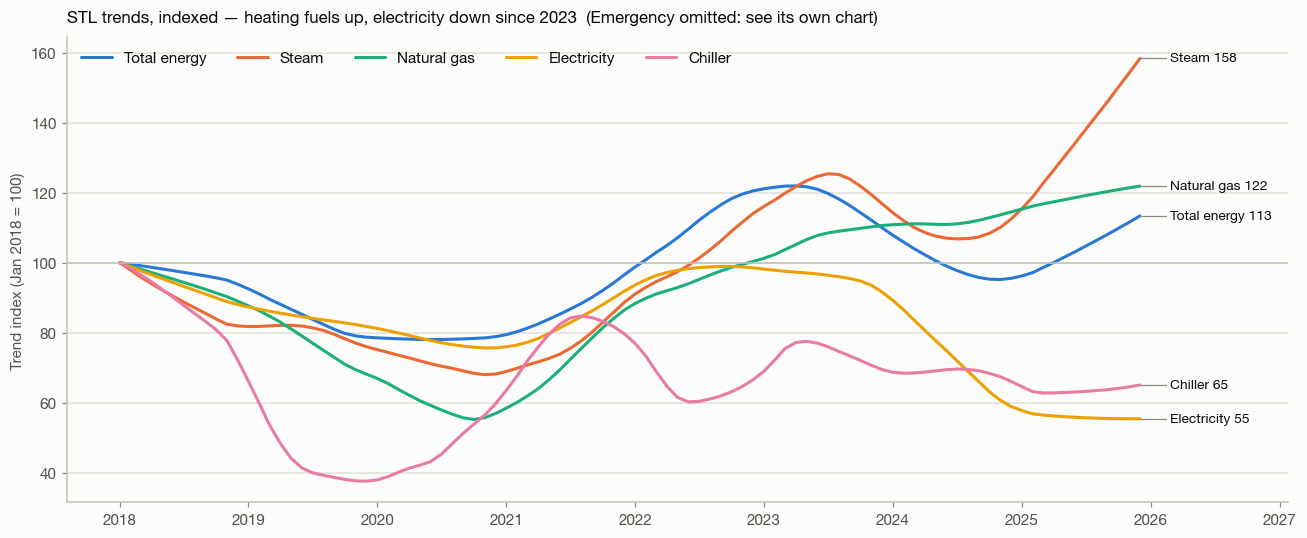

In [36]:
# All trends on one chart, indexed to Jan 2018 = 100 so different units can be compared
fig, ax = plt.subplots(figsize=(12, 5))
trend_idx = pd.DataFrame({m: r.trend / r.trend.iloc[0] * 100 for m, r in stl_results.items() if m != "Emergency"})
trend_names = ["Total energy", "Steam", "Natural gas", "Electricity", "Chiller"]
for name, color in zip(trend_names, SERIES):
    t = trend_idx[name]
    ax.plot(t.index, t, color=color, linewidth=2, label=name)
# end labels: spread apart by a minimum gap, joined to their line end by a thin leader
ends = sorted(((trend_idx[n].iloc[-1], n) for n in trend_names))
label_y, min_gap = [], 6
for v, _ in ends:
    label_y.append(max(v, label_y[-1] + min_gap) if label_y else v)
x_end, x_lab = trend_idx.index[-1], trend_idx.index[-1] + pd.Timedelta(days=75)
for (v, n), y in zip(ends, label_y):
    ax.plot([x_end, x_lab], [v, y], color=MUTED, linewidth=0.8)
    ax.text(x_lab + pd.Timedelta(days=10), y, f"{n} {v:.0f}", va="center", fontsize=9, color=INK)
ax.axhline(100, color=AXIS, linewidth=1)
ax.set_ylabel("Trend index (Jan 2018 = 100)")
ax.set_title("STL trends, indexed — heating fuels up, electricity down since 2023  (Emergency omitted: see its own chart)", pad=10)
ax.legend(loc="upper left", ncol=5)
ax.set_xlim(right=trend_idx.index[-1] + pd.Timedelta(days=420))
fig.tight_layout()
fig.savefig(PLOT_DIR / "19_stl_trends_indexed.png")
plt.show()

## 10 · Year-over-year comparison
Comparing each month with the same month in other years removes seasonality without any modelling.

First: **2025 against the 2018–2024 range** for every calendar month. The shaded band is the lowest-to-highest value seen in that month over 2018–2024, the gray line is the median, and the blue line is 2025.

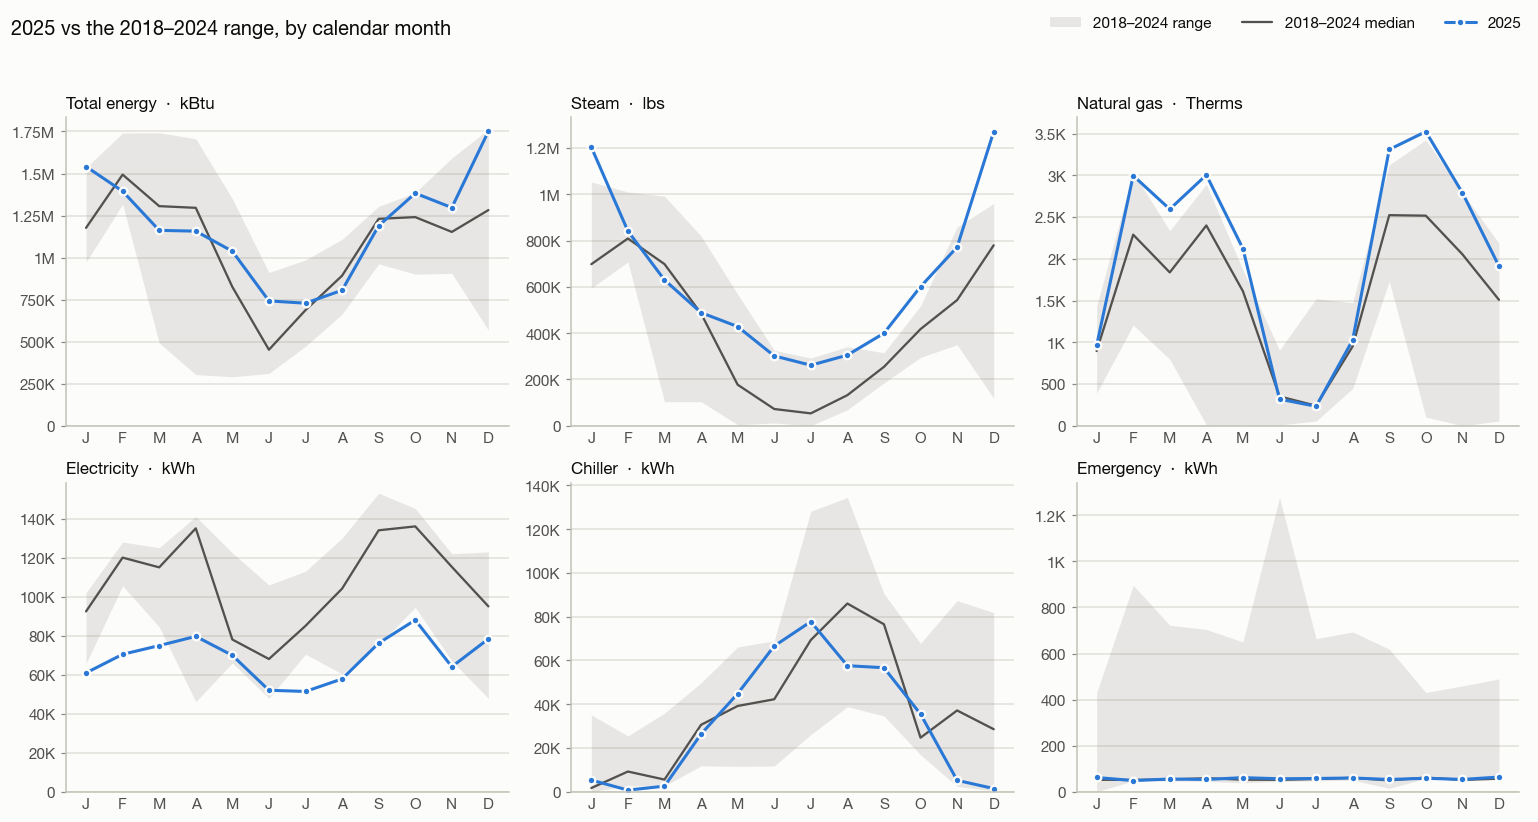

In [37]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
mon = df.index.month
last = df.index.year.max()
hist = df[df.index.year < last]
cur = df[df.index.year == last]
for ax, name in zip(axes.flat, rows):
    g = hist[name].groupby(hist.index.month)
    lo, hi, med = g.min(), g.max(), g.median()
    ax.fill_between(lo.index, lo, hi, color=MUTED, alpha=0.18, linewidth=0, label=f"2018–{last-1} range")
    ax.plot(med.index, med, color=INK2, linewidth=1.5, label=f"2018–{last-1} median")
    c = cur[name]
    ax.plot(c.index.month, c.values, color=BLUE, linewidth=2, marker="o", markersize=5,
            markeredgecolor=SURFACE, markeredgewidth=1.5, label=str(last))
    ax.set_title(f"{name}  ·  {units[name]}")
    ax.set_xticks(range(1, 13), months)
    ax.tick_params(axis="x", length=0)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(compact))
    ax.set_ylim(bottom=0)
h, l = axes.flat[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper right", ncol=3, bbox_to_anchor=(1, 1.0))
fig.suptitle(f"{last} vs the 2018–{last-1} range, by calendar month", x=0.01, ha="left", fontsize=13, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(PLOT_DIR / "20_yoy_current_vs_range.png")
plt.show()

Next: **month-over-same-month-last-year % change** for every meter. Blue = lower than the same month a year earlier, red = higher, gray = about the same. Colours are capped at ±100%; months where the previous year's value was near zero (< 5% of that month's median) are left blank, because the % change there is meaningless.

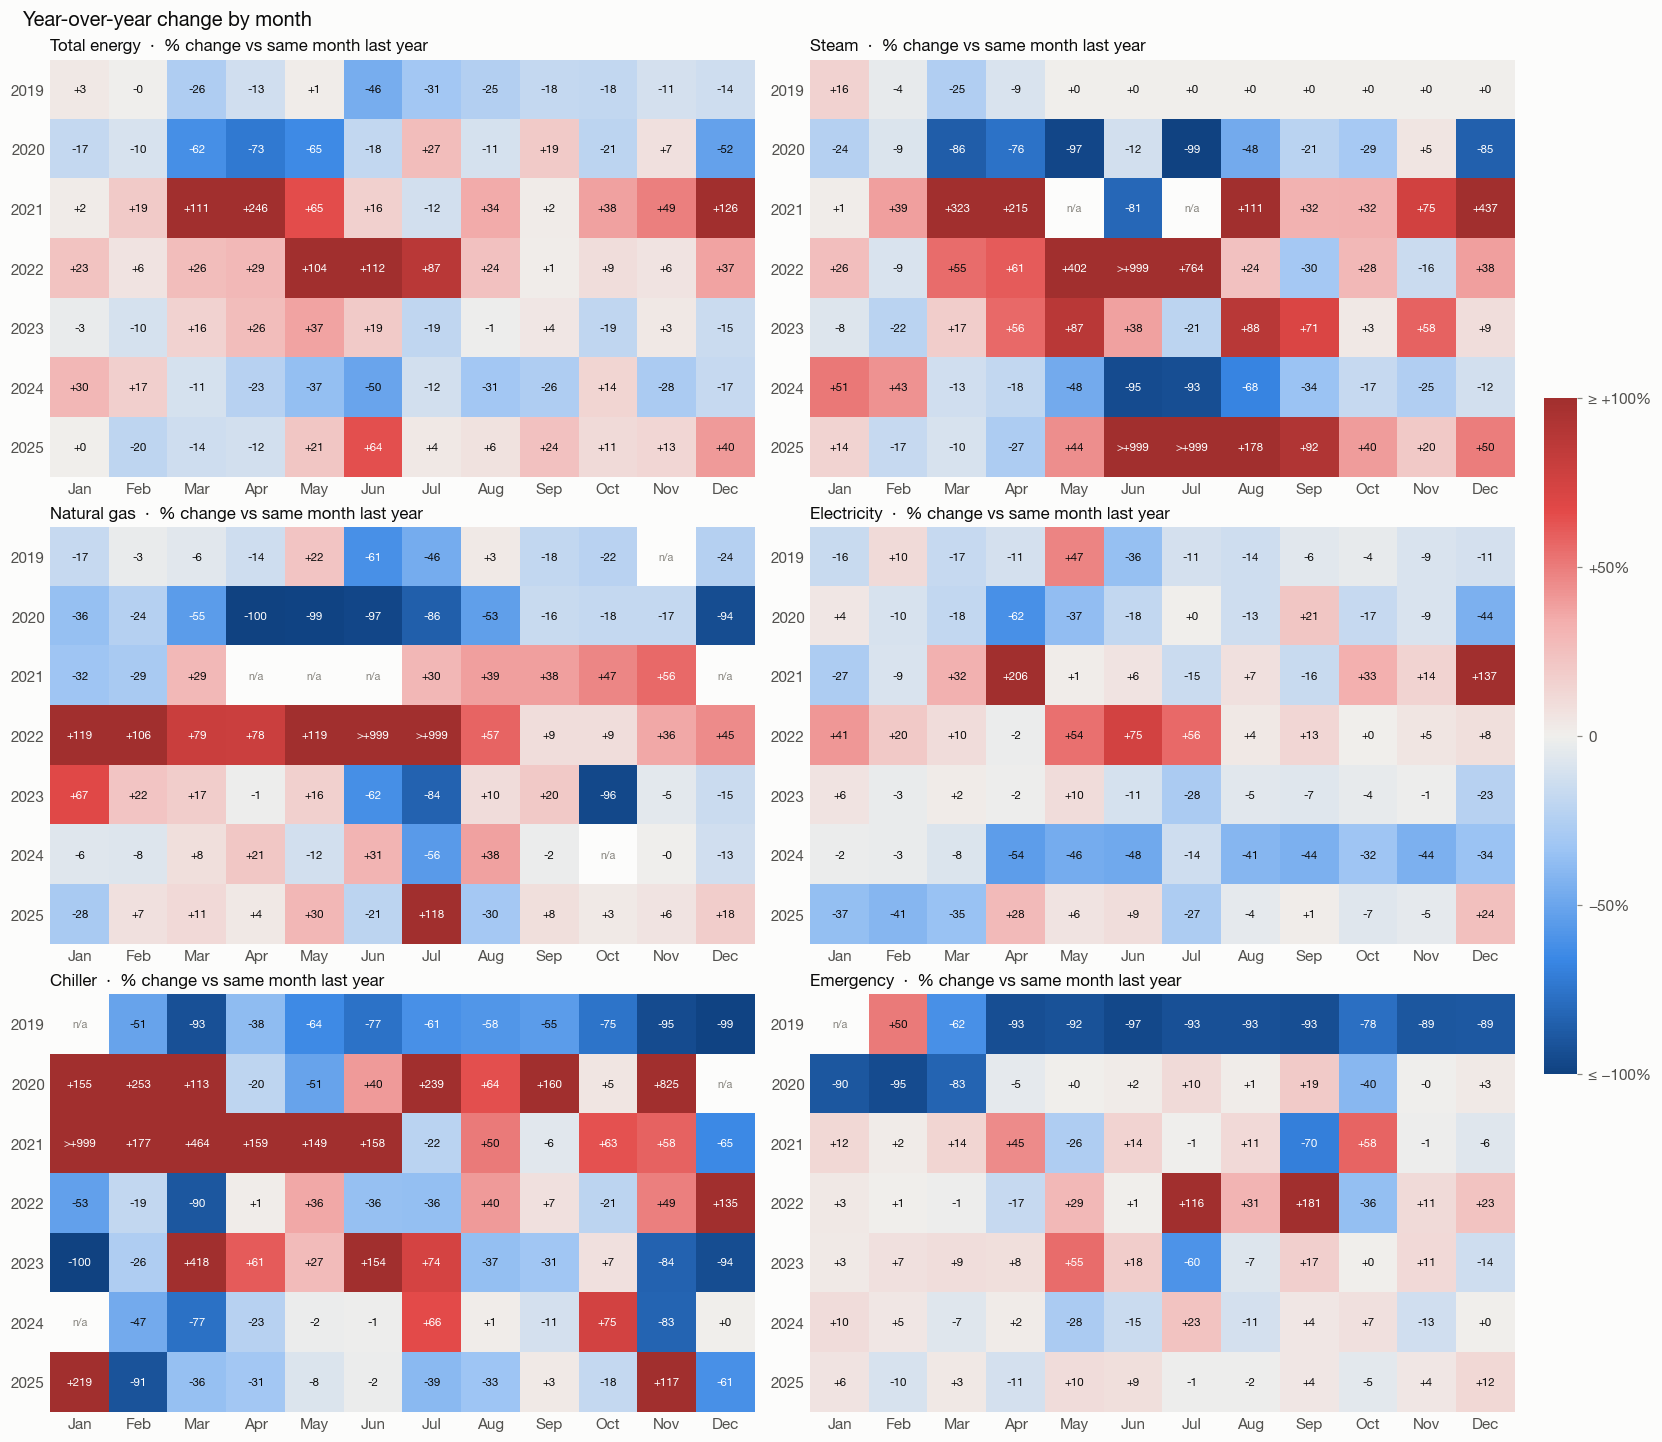

In [38]:
from matplotlib.colors import TwoSlopeNorm

div_cmap = LinearSegmentedColormap.from_list(
    "div_blue_red", ["#104281", "#3987e5", "#9ec5f4", "#f0efec", "#f3b0af", "#e34948", "#a12f2e"])

yoy = {}
for name in rows:
    s = df[name]
    prev = s.shift(12)
    typical = s.groupby(s.index.month).transform("median")
    pct = (s / prev - 1) * 100
    pct[(prev < 0.05 * typical) | prev.isna()] = np.nan
    yoy[name] = pct.groupby([pct.index.year, pct.index.month]).first().unstack().loc[2019:]

fig, axes = plt.subplots(3, 2, figsize=(15, 13), layout="constrained")
for ax, name in zip(axes.flat, rows):
    g = yoy[name]
    im = ax.imshow(g.clip(-100, 100).values, cmap=div_cmap, norm=TwoSlopeNorm(0, -100, 100), aspect="auto")
    for i in range(g.shape[0]):
        for j in range(g.shape[1]):
            v = g.values[i, j]
            if np.isnan(v):
                ax.text(j, i, "n/a", ha="center", va="center", fontsize=7, color=MUTED)
                continue
            txt = f"{v:+.0f}" if abs(v) < 1000 else (">+999" if v > 0 else "<-999")
            ax.text(j, i, txt, ha="center", va="center", fontsize=7.5,
                    color="white" if abs(v) > 55 else INK)
    ax.set_xticks(range(12), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
    ax.set_yticks(range(g.shape[0]), g.index)
    ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.tick_params(length=0)
    ax.set_title(f"{name}  ·  % change vs same month last year")
cb = fig.colorbar(im, ax=axes, shrink=0.5, pad=0.02, ticks=[-100, -50, 0, 50, 100])
cb.ax.set_yticklabels(["≤ −100%", "−50%", "0", "+50%", "≥ +100%"])
cb.outline.set_visible(False)
fig.suptitle("Year-over-year change by month", x=0.01, ha="left", fontsize=13, fontweight="semibold")
fig.savefig(PLOT_DIR / "21_yoy_monthly_change_heatmap.png")
plt.show()

Finally, **annual totals with year-over-year % change** for each meter.

In [39]:
annual_tot = df.groupby(df.index.year).sum()
annual_yoy = annual_tot.pct_change().mul(100).round(1)
annual_yoy.loc[annual_tot.index[0]] = np.nan
annual_tot.index.name = annual_yoy.index.name = "year"
out = pd.concat({"total": annual_tot.round(0), "YoY %": annual_yoy}, axis=1).swaplevel(axis=1)
out[[c for m in rows for c in [(m, "total"), (m, "YoY %")]]]

Total energy            Steam       Natural gas       Electricity        \
            total YoY %      total YoY %       total YoY %       total YoY %   
year                                                                           
2018   13841855.0   NaN  5199900.0   NaN     18232.0   NaN   1376000.0   NaN   
2019   11715463.0 -15.4  4981600.0  -4.2     17227.0  -5.5   1270846.0  -7.6   
2020    8601242.0 -26.6  2635955.0 -47.1      8421.0 -51.1   1055715.0 -16.9   
2021   12124848.0  41.0  4551900.0  72.7     13918.0  65.3   1234449.0  16.9   
2022   15304832.0  26.2  5996600.0  31.7     22844.0  64.1   1450371.0  17.5   
2023   15541154.0   1.5  7148700.0  19.2     20247.0 -11.4   1371143.0  -5.5   
2024   13318759.0 -14.3  6002700.0 -16.0     23738.0  17.2    937649.0 -31.6   
2025   14192109.0   6.6  7505827.0  25.0     24797.0   4.5    823365.0 -12.2   

       Chiller        Emergency        
         total  YoY %     total YoY %  
year                                   
2018  595254.0    NaN    7308.0   NaN  
2019  176727.0  -70.3    2085.0 -71.5  
2020  435106.0  146.2     595.0 -71.5  
2021  559110.0   28.5     619.0   4.1  
2022  584539.0    4.5     713.0  15.1  
2023  467129.0  -20.1     692.0  -3.0  
2024  487242.0    4.3     669.0  -3.3  
2025  380188.0  -22.0     678.0   1.4